In [ ]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML


In [ ]:
all_books = []

for page in range(1, 51):

    url = f"https://books.toscrape.com/catalogue/page-{page}.html"

    response = requests.get(url)

    soup = BeautifulSoup(response.text, "html.parser")

    books = soup.find_all("article", class_="product_pod")

    for book in books:

        title = book.h3.a["title"]

        price = book.find("p", class_="price_color").text

        rating = book.p["class"][1]

        availability = book.find(
            "p", class_="instock availability"
        ).text.strip()

        all_books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability
        })

print(len(all_books))

1000


In [ ]:
df = pd.DataFrame(all_books)

In [ ]:
df.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [ ]:
df.shape

(1000, 4)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Title         1000 non-null   object
 1   Price         1000 non-null   object
 2   Rating        1000 non-null   object
 3   Availability  1000 non-null   object
dtypes: object(4)
memory usage: 31.4+ KB


In [ ]:
df.to_csv("books_dataset.csv", index=False)

In [ ]:
df.isnull().sum()

,0
Title,0
Price,0
Rating,0
Availability,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
Title,object
Price,object
Rating,object
Availability,object


In [ ]:
def clean_price(x):
    return float(x.replace("£", "").replace("Â", "").strip())

df["Price"] = df["Price"].map(clean_price)

df.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,Three,In stock
1,Tipping the Velvet,53.74,One,In stock
2,Soumission,50.10,One,In stock
3,Sharp Objects,47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,54.23,Five,In stock


In [ ]:

# Statistical Summary of Book Prices
display(HTML("<b>Statistical Summary of Book Prices:</b>"))
display(df["Price"].describe())
display(HTML("<div style='height: 30px;'></div>"))

# Top 5 Most Expensive Books
display(HTML("<b>Top 5 Most Expensive Books:</b>"))
display(df.nlargest(5, "Price"))
display(HTML("<div style='height: 30px;'></div>"))

# Top 5 Cheapest Books
display(HTML("<b>Top 5 Cheapest Books:</b>"))
display(df.nsmallest(5, "Price"))
display(HTML("<div style='height: 30px;'></div>"))

# Number of Books by Rating
display(HTML("<b>Number of Books by Rating:</b>"))
display(df["Rating"].value_counts().sort_index())
display(HTML("<div style='height: 30px;'></div>"))

# Average Price by Rating
display(HTML("<b>Average Price by Rating:</b>"))
display(df.groupby("Rating")["Price"].mean())

,Price
count,1000.00000
mean,35.07035
std,14.44669
min,10.00000
25%,22.10750
50%,35.98000
75%,47.45750
max,59.99000


,Title,Price,Rating,Availability
648,The Perfect Play (Play by Play #1),59.99,Three,In stock
617,Last One Home (New Beginnings #1),59.98,Three,In stock
860,Civilization and Its Discontents,59.95,Two,In stock
560,The Barefoot Contessa Cookbook,59.92,Five,In stock
366,The Diary of a Young Girl,59.90,Three,In stock


,Title,Price,Rating,Availability
638,An Abundance of Katherines,10.00,Five,In stock
501,The Origin of Species,10.01,Four,In stock
716,The Tipping Point: How Little Things Can Make ...,10.02,Two,In stock
84,Patience,10.16,Three,In stock
302,Greek Mythic History,10.23,Five,In stock


,count
Rating,
Five,196
Four,179
One,226
Three,203
Two,196


,Price
Rating,
Five,35.374490
Four,36.093296
One,34.561195
Three,34.692020
Two,34.810918


,count
Price_Range,
0-20,196
20-40,401
40-60,403
60-80,0


,Price
Price_Range,
0-20,14.798571
20-40,30.063067
40-60,49.912010


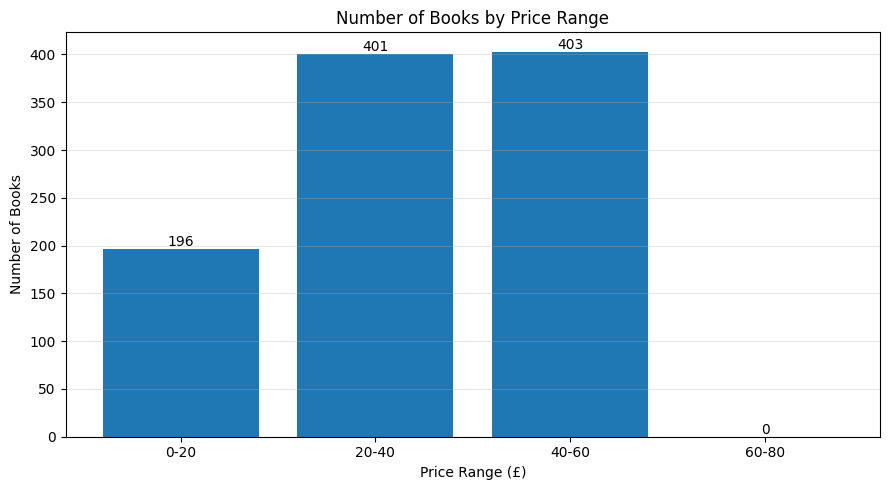

In [ ]:
# Book Distribution by Price Range

bins = [0, 20, 40, 60, 80]
labels = ["0-20", "20-40", "40-60", "60-80"]

df["Price_Range"] = pd.cut(df["Price"], bins=bins, labels=labels)

display(HTML("<b>Number of Books by Price Range:</b>"))
display(df["Price_Range"].value_counts().sort_index())

display(HTML("<div style='height: 30px;'></div>"))

# Average Price by Price Range

display(HTML("<b>Average Price by Price Range:</b>"))
display(df.groupby("Price_Range", observed=True)["Price"].mean())

price_counts = df["Price_Range"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

bars=plt.bar(price_counts.index.astype(str), price_counts.values)
plt.bar_label(bars)
plt.title("Number of Books by Price Range")
plt.xlabel("Price Range (£)")
plt.ylabel("Number of Books")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



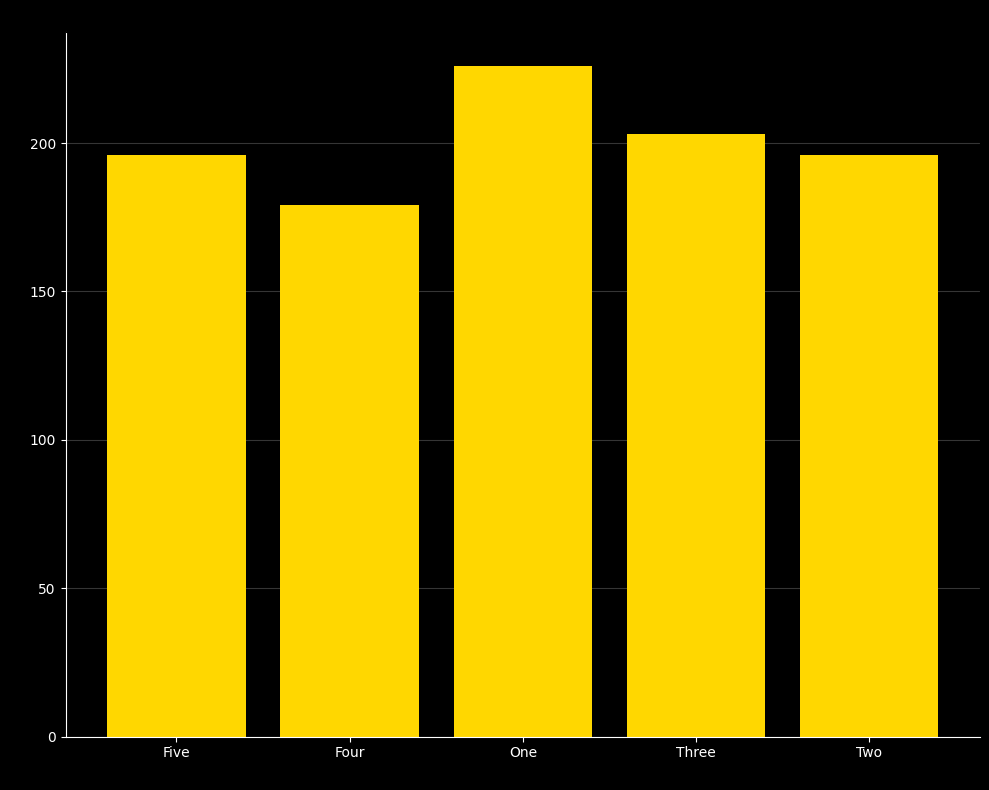

In [84]:
# Book Distribution by Rating

rating_counts = df["Rating"].value_counts().sort_index()

fig, ax=plt.subplots(figsize=(10,8))
ax.figsize=(9, 5)

fig.set_facecolor('black')
ax.set_facecolor('black')
ax.bar(rating_counts.index, rating_counts.values, color="gold")

ax.set_title("Number of Books by Rating")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of Books")
ax.tick_params(axis='both', colors='white')
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
#for spine in ax.spines.values():
#    spine.set_color("white")
ax.spines["left"].set_color("white")
ax.spines["bottom"].set_color("white")
plt.tight_layout()
plt.show()

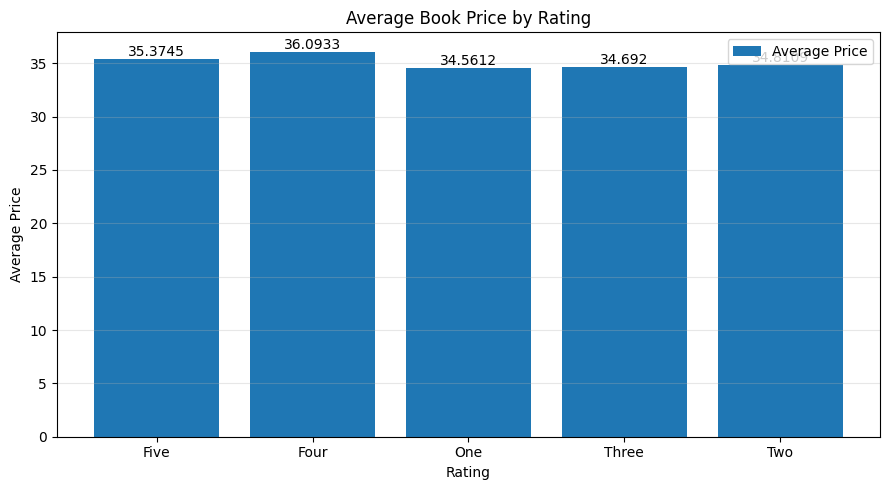

In [ ]:
# Average Book Price by Rating

avg_price = df.groupby("Rating")["Price"].mean()

plt.figure(figsize=(9, 5))

bars=plt.bar(avg_price.index, avg_price.values, label="Average Price")

plt.title("Average Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price")
plt.bar_label(bars)
plt.legend()

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

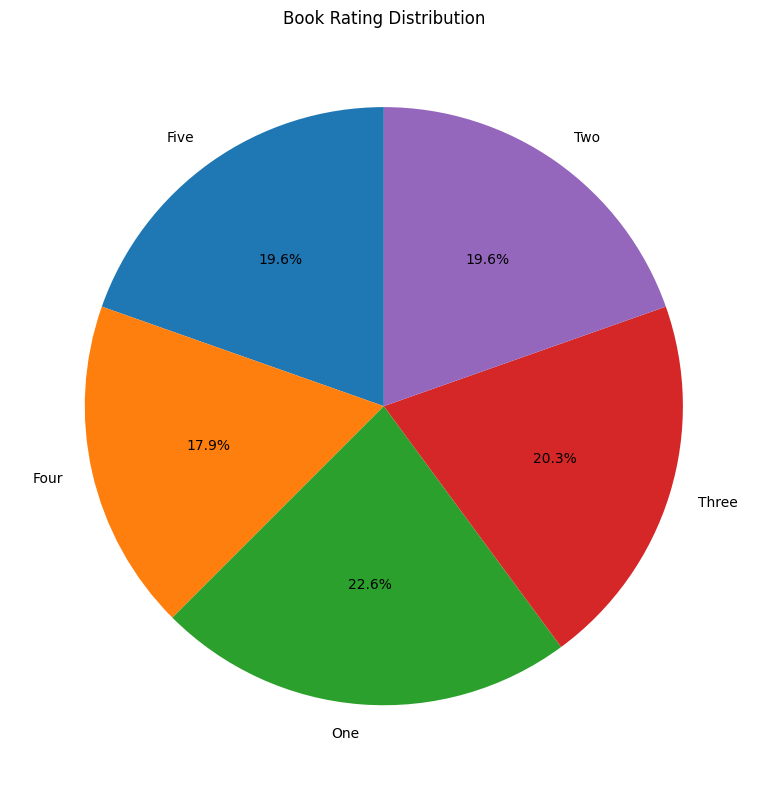

In [ ]:
# Book Rating Distribution

rating_counts = df["Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 8))

plt.pie(
    rating_counts.values,
    labels=rating_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    labeldistance=1.1
)

plt.title("Book Rating Distribution")
plt.tight_layout()
plt.show()

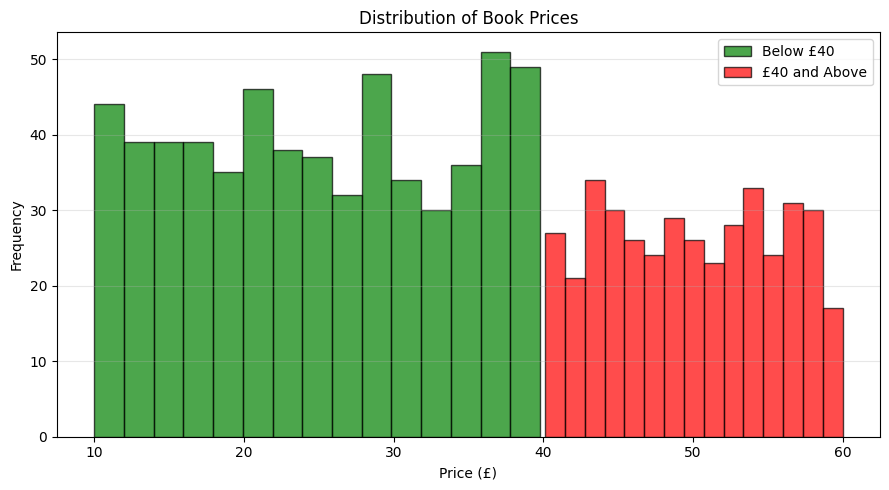

In [83]:
# Price Distribution by Condition

plt.figure(figsize=(9, 5))

plt.hist(
    df.loc[df["Price"] < 40, "Price"],
    bins=15,
    color="green",
    edgecolor="black",
    alpha=0.7,
    label="Below £40"
)

plt.hist(
    df.loc[df["Price"] >= 40, "Price"],
    bins=15,
    color="red",
    edgecolor="black",
    alpha=0.7,
    label="£40 and Above"
)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

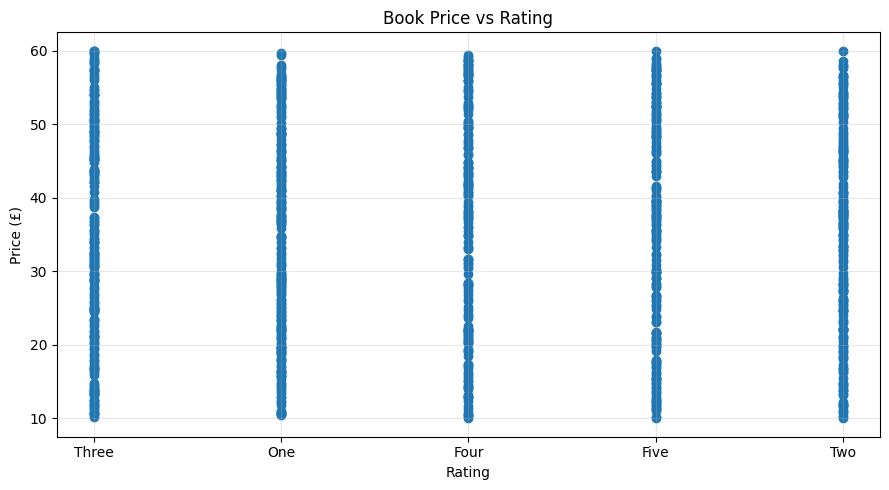

In [ ]:
# Relationship Between Book Price and Rating

plt.figure(figsize=(9, 5))

plt.scatter(df["Rating"], df["Price"])

plt.title("Book Price vs Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_731/3631351460.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(rating_groups, labels=sorted(df["Rating"].unique()))


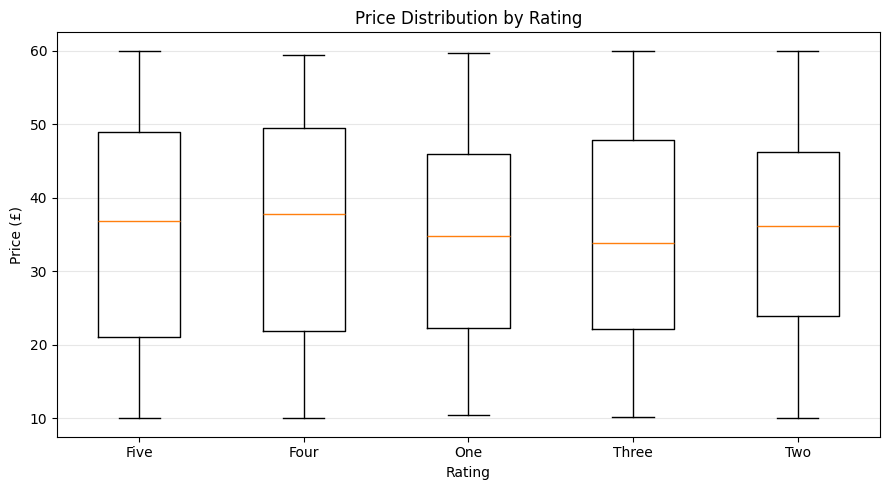

In [82]:
# Price Distribution by Rating

rating_groups = [
    df.loc[df["Rating"] == rating, "Price"]
    for rating in sorted(df["Rating"].unique())
]

plt.figure(figsize=(9, 5))

plt.boxplot(rating_groups, labels=sorted(df["Rating"].unique()))

plt.title("Price Distribution by Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

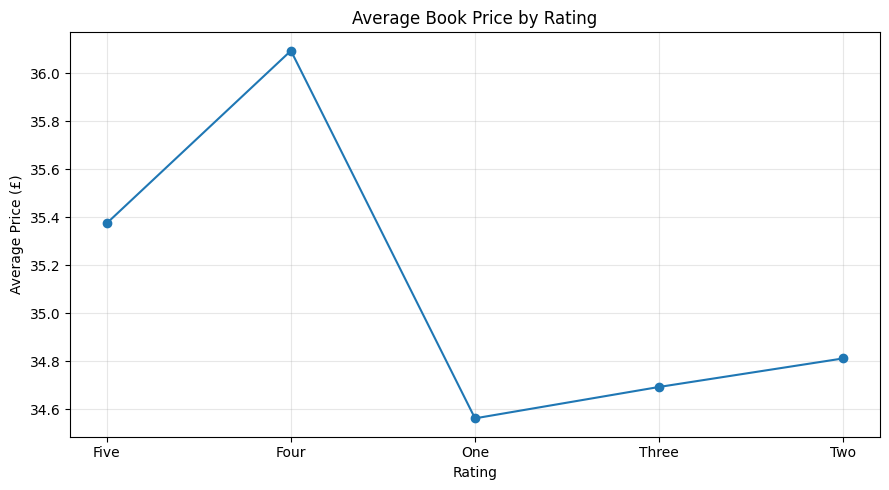

In [ ]:
# Average Book Price by Rating

avg_price = df.groupby("Rating")["Price"].mean()

plt.figure(figsize=(9, 5))

plt.plot(avg_price.index, avg_price.values, marker="o")

plt.title("Average Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price (£)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

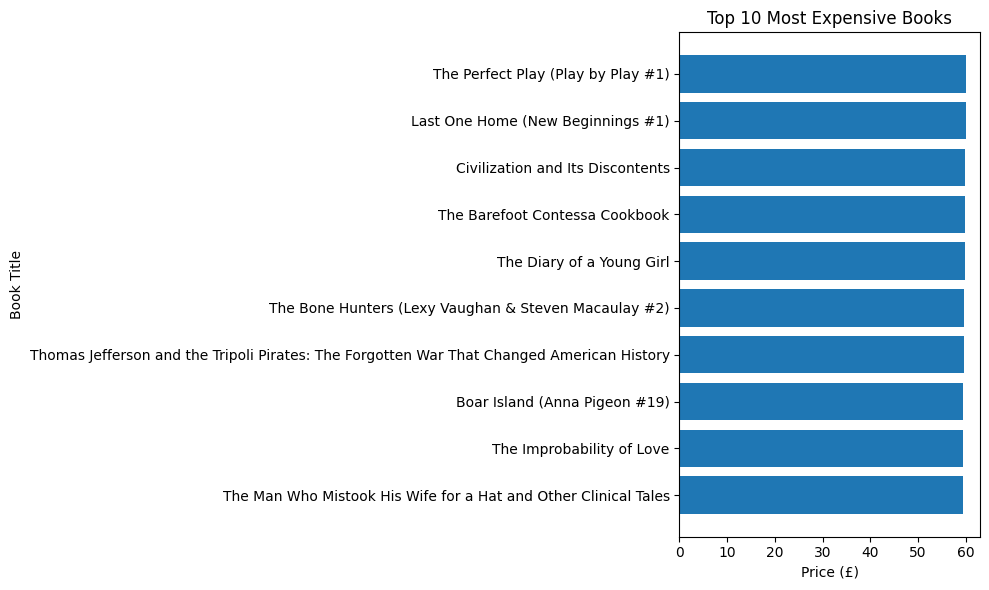

In [78]:
# Top 10 Most Expensive Books

top_10 = df.nlargest(10, "Price")

plt.figure(figsize=(10, 6))

plt.barh(top_10["Title"], top_10["Price"])

plt.title("Top 10 Most Expensive Books")
plt.xlabel("Price (£)")
plt.ylabel("Book Title")

top_10["Title"] = top_10["Title"].apply(divide)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

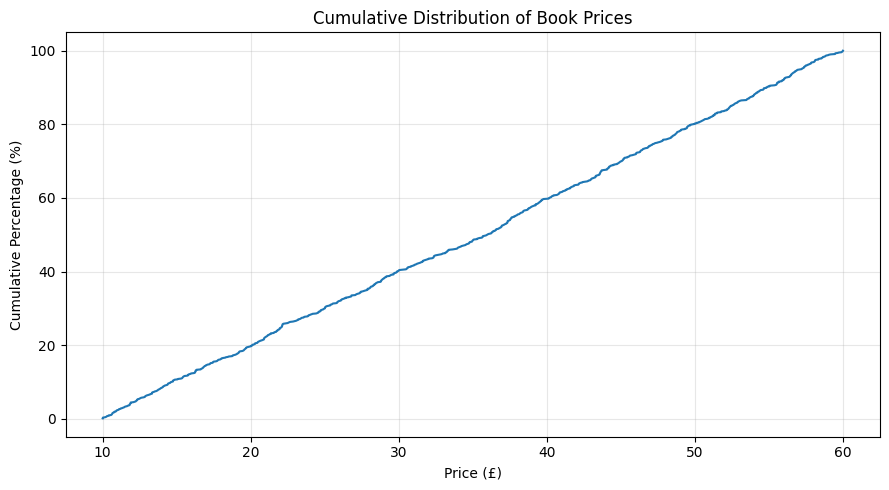

In [79]:
# Cumulative Distribution of Book Prices

prices = df["Price"].sort_values()

cumulative_percentage = range(1, len(prices) + 1)

plt.figure(figsize=(9, 5))

plt.plot(
    prices,
    [x / len(prices) * 100 for x in cumulative_percentage],
linestyle="-")

plt.title("Cumulative Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Cumulative Percentage (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

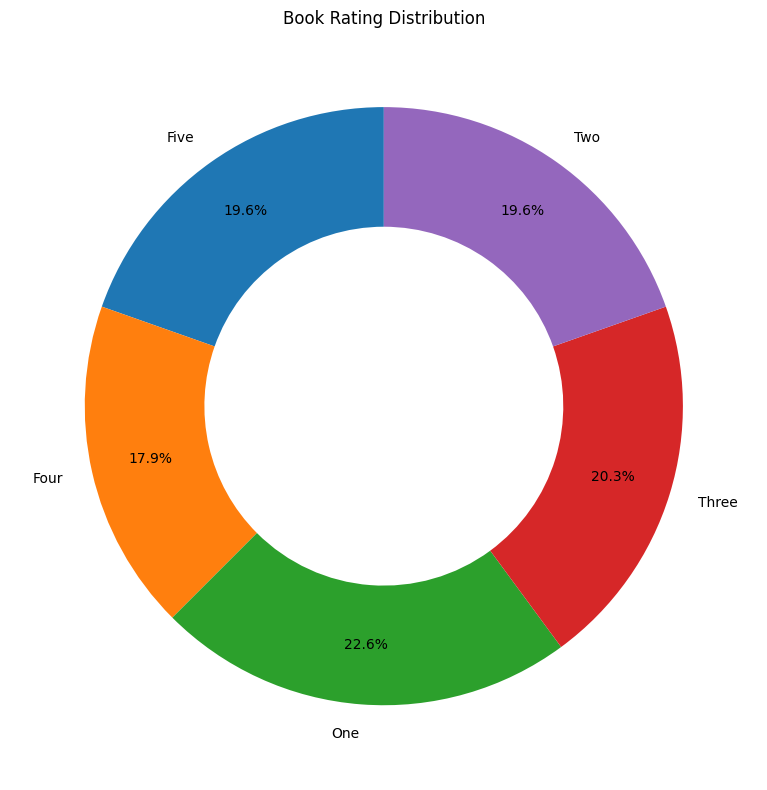

In [81]:
# Book Rating Distribution

rating_counts = df["Rating"].value_counts().sort_index()

plt.figure(figsize=(8, 8))

plt.pie(
    rating_counts.values,
    labels=rating_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4},
    pctdistance=0.8
)

plt.title("Book Rating Distribution")
plt.tight_layout()
plt.show()

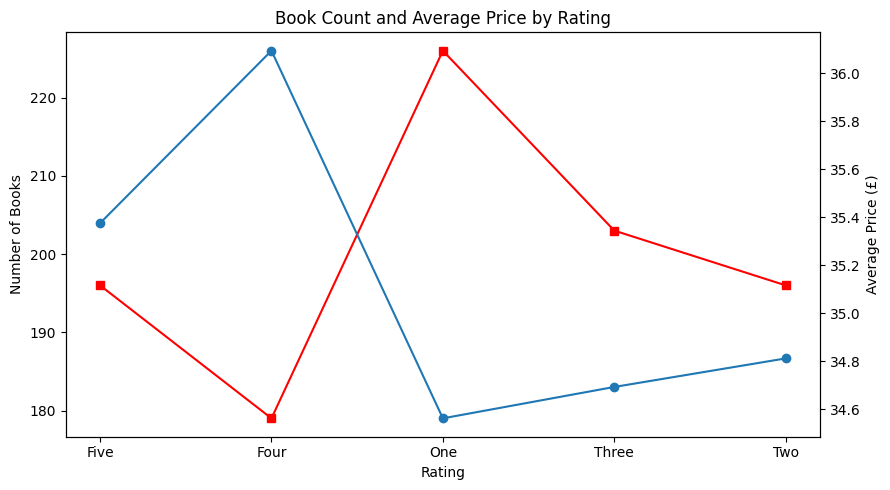

In [80]:
# Book Count and Average Price by Rating

rating_count = df["Rating"].value_counts().sort_index()

avg_price = df.groupby("Rating")["Price"].mean()

fig, ax1 = plt.subplots(figsize=(9, 5))

# First Y-axis: Number of Books
ax1.plot(rating_count.index, rating_count.values, color="red", marker="s")

ax1.set_xlabel("Rating")
ax1.set_ylabel("Number of Books")
ax1.set_title("Book Count and Average Price by Rating")

# Second Y-axis: Average Price
ax2 = ax1.twinx()

ax2.plot(avg_price.index, avg_price.values, marker="o")

ax2.set_ylabel("Average Price (£)")

plt.tight_layout()
plt.show()